# Experiment 08 — SciConv fact recovery

Offline exploratory reanalysis inspired by [PR #17](https://github.com/MatrAIx-ai/PersonaScienceBench/pull/17) and [PR #12](https://github.com/MatrAIx-ai/PersonaScienceBench/pull/12). Uses the frozen Astra panel and existing judge outputs. **No model calls.**

Run all cells in a Python kernel with NumPy and Matplotlib. Original outcomes are primary; repairs remain a separate sensitivity. The [plan](PLAN.md) tracks the implemented analysis and future controlled follow-up.

In [1]:
from pathlib import Path
import importlib.util, inspect, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Experiment/08_sciconv_fact_recovery/code/analyze.py').exists())
BASE = ROOT / 'Experiment/08_sciconv_fact_recovery'
spec = importlib.util.spec_from_file_location('fact_recovery', BASE / 'code/analyze.py')
analysis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis)
snapshot = analysis.read(BASE / 'data/snapshot.json')
print('Snapshot:', snapshot['captured_at_utc'])
print('Snapshot SHA256:', analysis.digest(BASE / 'data/snapshot.json'))
print('Source result files:', len(snapshot['provenance']))
print('Frozen per-condition model configs:', len(snapshot['model_configs']))
print('Episode records:', len(snapshot['episodes']))


Snapshot: 2026-09-30T15:30:43.967461+00:00
Snapshot SHA256: 3ae3f86554fe7027c14f04ce2031d53a09265006d6622a5c2c80747788f55662
Source result files: 12
Frozen per-condition model configs: 18
Episode records: 1440


## Metric and eligibility

Only the **20 disambiguation cases** have a deleted-fact denominator. The other 20 inconsistency cases remain explicitly excluded. Read native saved `score = k/n`, require integer counts with `0 ≤ k ≤ n`, `n > 0`, and check n against the native issue count. An invalid or absent judgement is missing, not zero. Recovery share is measured before the intent gate; FRR is separately reported. No reference facts or conversations are copied into this notebook.

In [2]:
print(inspect.getsource(analysis.parse_fraction))
from collections import Counter
for view in ['original', 'after_repair']:
    rows = [r for r in snapshot['episodes'] if r['view'] == view]
    print(view, Counter(r['status'] for r in rows))


def parse_fraction(value,expected=None):
    match=re.fullmatch(r'\s*(\d+)\s*/\s*(\d+)\s*',str(value))
    if not match:raise ValueError('Malformed recovery fraction')
    k,n=map(int,match.groups())
    if n<=0 or not 0<=k<=n:raise ValueError('Invalid recovery counts')
    if expected is not None and n!=expected:raise ValueError('Judge denominator does not match native issue count')
    return k,n

original Counter({'excluded_inconsistency': 360, 'scored': 359, 'infrastructure_error': 1})
after_repair Counter({'excluded_inconsistency': 360, 'scored': 360})


## Aggregation and confidence intervals

Average each case’s available trials, then give each case equal weight. Paired persona-off contrasts match case **and trial** before aggregation. Resample study clusters within domains, preserving observed domain weights: 20,000 percentile-bootstrap draws, seed 20261001. Trials are not treated as independent cases. CIs condition on the observed trial outcomes and are pointwise, not simultaneous or corrected significance tests. Domain/study strata with few cases can have unstable or degenerate intervals.

The following cell exposes the implementation used by the notebook and standalone report.

In [3]:
print(inspect.getsource(analysis.task_means))
print(inspect.getsource(analysis.ci))
print(inspect.getsource(analysis.analyze))
summary = analysis.analyze(snapshot)
assert summary == analysis.read(BASE / 'data/summary.json')
print('Recomputed summary matches the saved report exactly.')


def task_means(rows,metric):
    cases=defaultdict(list)
    for r in rows:
        if r['status']=='scored' and r.get(metric) is not None:cases[r['case']].append(r)
    return [{'case':case,'domain':rs[0]['domain'],'study_id':rs[0]['study_id'],'value':float(np.mean([r[metric] for r in rs])),'episodes':len(rs)} for case,rs in sorted(cases.items())]

def ci(group,rng):
    if not group:return {'mean':None,'ci95':None,'cases':0,'episodes':0,'clusters':0}
    boots=np.zeros(RESAMPLES);clusters_total=0
    for domain in sorted({r['domain'] for r in group}):
        sub=[r for r in group if r['domain']==domain];clusters=sorted({r['study_id'] for r in sub});clusters_total+=len(clusters)
        sums=np.array([sum(r['value'] for r in sub if r['study_id']==c) for c in clusters]);counts=np.array([sum(r['study_id']==c for r in sub) for c in clusters])
        weights=rng.multinomial(len(clusters),np.ones(len(clusters))/len(clusters),size=RESAMPLES)
        boots+=(weights@sums)/(weights@counts)*

## Original three-trial results

The primary panel is fixed before this reanalysis. No difficulty or persona-effect filtering is applied. Recovery and FRR both use percentages here; paired differences use percentage points.

In [4]:
print(analysis.table(summary))


| Persona | Recovery % [95% CI] | Paired Δ vs off (pp) [95% CI] | FRR % | Cases / episodes | Cap hits (all) |
|---|---|---|---:|---:|---:|
| Off | 84.7 [71.8, 96.0] | reference | 78.3 | 20 / 60 | 8 |
| 148 | 87.1 [75.1, 97.1] | 2.4 [-2.9, 8.5] | 83.3 | 20 / 60 | 5 |
| 155 | 88.6 [77.1, 99.8] | 3.9 [-0.1, 10.0] | 80.0 | 20 / 60 | 8 |
| 089 | 90.9 [80.9, 98.5] | 6.2 [-0.7, 13.1] | 81.7 | 20 / 59 | 9 |
| 001 | 88.7 [77.5, 98.6] | 4.0 [0.2, 10.5] | 81.7 | 20 / 60 | 7 |
| 127 | 88.3 [76.7, 100.0] | 3.6 [-0.5, 10.0] | 83.3 | 20 / 60 | 7 |


## Ten-question-limit sensitivity

Infer a cap hit from at least ten researcher replies, following PR #17. Exclude either affected member of each matched comparison. This is a sensitivity analysis for known last-answer handling, not a fix to the historical episodes.

In [5]:
print(analysis.table(summary, "exclude_question_limit"))


| Persona | Recovery % [95% CI] | Paired Δ vs off (pp) [95% CI] | FRR % | Cases / episodes | Cap hits (all) |
|---|---|---|---:|---:|---:|
| Off | 87.0 [74.1, 100.0] | reference | 87.0 | 18 / 52 | 8 |
| 148 | 89.5 [77.2, 98.2] | 2.0 [-3.9, 9.8] | 89.5 | 19 / 55 | 5 |
| 155 | 91.1 [80.5, 99.9] | 3.8 [-0.3, 11.6] | 85.1 | 19 / 52 | 8 |
| 089 | 94.1 [82.4, 100.0] | 7.8 [0.0, 15.7] | 92.2 | 17 / 50 | 9 |
| 001 | 90.7 [79.6, 100.0] | 3.7 [0.0, 11.1] | 88.9 | 18 / 53 | 7 |
| 127 | 90.8 [80.3, 100.0] | 3.2 [-0.9, 10.6] | 89.5 | 19 / 53 | 7 |


## Exploratory baseline difficulty screen

This describes the current cases using persona-off only. Multi-fact cases: recovery >90% is near ceiling; <30% is low; otherwise intermediate. Single-fact cases are tracked separately. These labels do **not** select the primary analysis. A future screened experiment needs fresh confirmation and held-out evaluation.

In [6]:
for row in summary['exploratory_difficulty_screen']:
    print(row['case'], 'facts=', row['facts_total'], 'mean=', round(row['value'], 3), 'band=', row['band'])
print('Counts:', Counter(r['band'] for r in summary['exploratory_difficulty_screen']))


fluids/disambiguation/case_001 facts= 3 mean= 1.0 band= near_ceiling
fluids/disambiguation/case_006 facts= 2 mean= 1.0 band= near_ceiling
fluids/disambiguation/case_043 facts= 3 mean= 1.0 band= near_ceiling
foam/disambiguation/case_046 facts= 7 mean= 0.857 band= multi_fact_mid
foam/disambiguation/case_078 facts= 6 mean= 1.0 band= near_ceiling
foam/disambiguation/case_083 facts= 8 mean= 0.417 band= multi_fact_mid
matSci/disambiguation/case_012 facts= 2 mean= 1.0 band= near_ceiling
matSci/disambiguation/case_065 facts= 1 mean= 1.0 band= single_fact
matSci/disambiguation/case_069 facts= 2 mean= 0.333 band= multi_fact_mid
matToolUse/disambiguation/case_009 facts= 14 mean= 1.0 band= near_ceiling
matToolUse/disambiguation/case_236 facts= 1 mean= 1.0 band= single_fact
pde/disambiguation/case_107 facts= 1 mean= 1.0 band= single_fact
pde/disambiguation/case_156 facts= 4 mean= 1.0 band= near_ceiling
solMech/disambiguation/case_019 facts= 4 mean= 1.0 band= near_ceiling
solMech/disambiguation/case

## Revised manuscript figure

Python nature-figure workflow: 183 × 100 mm, restrained baseline/persona colors, editable text, panel labels and numeric CI bounds. Panel a establishes recovery levels; panel b shows matched effects. Intentional 6:5 panel widths allocate equal space per condition. The renderer blocks export if panel alignment fails. Final source, glyph-size and PDF collision audits are retained in `figures/qa/`. No data or statistics changed.


def plot(summary,show=False):
    plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],
        'font.size':7,'axes.labelsize':7,'axes.titlesize':8,'xtick.labelsize':6.5,'ytick.labelsize':6.5,
        'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':0.6,
        'xtick.major.width':0.6,'ytick.major.width':0.6,'xtick.major.size':2.5,'ytick.major.size':2.5,
        'pdf.fonttype':42,'svg.fonttype':'none','legend.frameon':False})
    p=summary['views']['original']['panels']['all']
    fig,axes=plt.subplots(1,2,figsize=(7.2047244094,3.9370078740),gridspec_kw={'width_ratios':[6,5]})
    fig.subplots_adjust(left=.085,right=.985,bottom=.255,top=.81,wspace=.28)
    rows=[]
    specs=[(axes[0],ARMS,LABELS,[p['arms'][a]['recovery_share'] for a in ARMS],'Fact recovery','Recovery (%)'),
           (axes[1],ARMS[1:],LABELS[1:],[p['paired_recovery_vs_off'][a] for a in ARMS[1:]],'Paired effect versus off','Change (percentage points)')]
    for letter,(ax

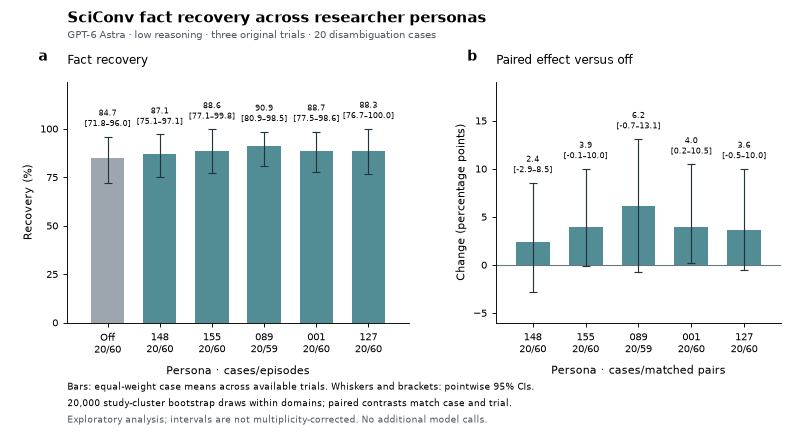

In [7]:
import sys
if str(BASE / "code") not in sys.path: sys.path.insert(0, str(BASE / "code"))
import plot_fact_recovery
print(inspect.getsource(plot_fact_recovery.plot))
figure = analysis.plot(summary, show=True)


## Repair sensitivity and outputs

The repaired result is a conditional additional attempt within the original trial, never a fourth trial. Earlier successes are reused. The frozen model configs specify Astra low despite the historical evaluator label containing `luna-judge`; the label is retained as provenance, not used to infer the model.

In [8]:
print('Episode recovery values changed after repair:', summary['original_vs_repair_changed'])
for arm, label in zip(analysis.ARMS, analysis.LABELS):
    s = summary['views']['after_repair']['panels']['all']['arms'][arm]['recovery_share']
    print(label, analysis.fmt(s), 'cases=', s['cases'], 'episodes=', s['episodes'])
analysis.save_report(snapshot, summary)
print('Report:', BASE / 'REPORT.md')


Episode recovery values changed after repair: 1
Off 84.7 [72.1, 96.0] cases= 20 episodes= 60
148 87.1 [75.2, 97.1] cases= 20 episodes= 60
155 88.6 [76.4, 99.8] cases= 20 episodes= 60
089 90.9 [80.9, 98.5] cases= 20 episodes= 60
001 88.7 [77.5, 98.6] cases= 20 episodes= 60
127 88.3 [76.2, 100.0] cases= 20 episodes= 60
Report: /net/spaces/scratch/siyangwu-scratch2/PersonaScienceBench/Experiment/08_sciconv_fact_recovery/REPORT.md


## Interpretation and planned follow-up

These are post-hoc descriptive results with five persona contrasts; do not choose a winner from an uncorrected interval. In particular, persona 001’s primary interval barely excludes zero and reaches zero when cap-hit episodes are removed. Most cases are near ceiling.

Next-stage controls documented in the [plan](PLAN.md): independent difficulty confirmation, multiple neutral paraphrases, fixed/versioned simulator switches, fresh replication, explicit multiplicity correction, and separately validated per-fact disclosure annotations. No new inference jobs are submitted by this notebook.

[Full report](REPORT.md) · [PDF](figures/fact_recovery.pdf) · [SVG](figures/fact_recovery.svg) · [Data](data/summary.json)